# Fine-tuning de uma LLM local para Text-to-SQL em português

**Problema escolhido:** analistas de uma loja virtual querem consultar o banco de dados fazendo perguntas em
português ("Quais os 5 produtos mais vendidos?") sem saber SQL. Treinamos uma LLM local para **converter a pergunta
em uma consulta SQL (SQLite)** que é executada no banco.

**Por que esse problema?** A saída é verificável de forma objetiva: executamos o SQL gerado e comparamos o
resultado com o da consulta correta (*execution accuracy*). Assim conseguimos comparar modelos e hiperparâmetros com números.

**LLM escolhida:** [`Qwen/Qwen2.5-Coder-0.5B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-Coder-0.5B-Instruct)
(licença Apache 2.0). Motivos:
- modelo *instruct* especializado em código (inclui SQL) e com bom suporte a português;
- 0,5 B de parâmetros cabe com folga nos 8 GB da RTX 3050, permitindo **vários experimentos** de hiperparâmetros;
- no final comparamos também com o irmão maior, `Qwen2.5-Coder-1.5B-Instruct`, para avaliar o efeito do tamanho do modelo.

**Técnica:** fine-tuning supervisionado (SFT) com **LoRA** (PEFT) em `bfloat16` na GPU, com laço de treino em PyTorch.

**Roteiro do notebook**
1. Verificação da GPU
2. Dados: banco SQLite e dataset pergunta → SQL
3. Linha de base: modelo sem treino (zero-shot)
4. Treino LoRA com diferentes hiperparâmetros
5. Comparação dos experimentos
6. Teste de parâmetros de geração (temperatura / amostragem)
7. Modelo maior (1,5 B)
8. Avaliação final e análise de erros
9. Salvando o melhor modelo para o frontend

In [1]:
import sys, os, json, time, math, gc, random, shutil, threading, subprocess
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import torch
import pandas as pd
import matplotlib.pyplot as plt
import pynvml
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging
from peft import LoraConfig, get_peft_model, PeftModel

from src.banco import criar_banco, conectar
from src.dataset import gerar_dataset
from src.avaliacao import avaliar, mensagens, INSTRUCAO_SISTEMA

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

PASTA_RES = RAIZ / "resultados"; PASTA_RES.mkdir(exist_ok=True)
PASTA_MOD = RAIZ / "modelos"; PASTA_MOD.mkdir(exist_ok=True)
DISPOSITIVO = "cuda"

## 1. Verificação da GPU
Todos os testes rodam na GPU. Abaixo, a saída do `nvidia-smi` e as informações vistas pelo PyTorch.

In [2]:
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
assert torch.cuda.is_available(), "CUDA não disponível!"
prop = torch.cuda.get_device_properties(0)
print(f"PyTorch {torch.__version__} | CUDA (PyTorch) {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")
print(f"GPU: {prop.name} | VRAM: {prop.total_memory / 1024**3:.1f} GB | Compute capability: {prop.major}.{prop.minor} "
      f"| SMs: {prop.multi_processor_count} | bfloat16: {torch.cuda.is_bf16_supported()}")

Thu Oct 15 16:14:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.14                 KMD Version: 617.14        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050      WDDM  |   00000000:09:00.0  On |                  N/A |
|  0%   42C    P8             16W /  130W |     609MiB /   8192MiB |     29%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Monitor simples (via NVML) que amostra utilização, memória, temperatura e potência da GPU em segundo plano durante o treino.

In [3]:
class MonitorGPU:
    def __init__(self, intervalo=0.5):
        self.intervalo, self.amostras = intervalo, []
    def _loop(self):
        pynvml.nvmlInit()
        h = pynvml.nvmlDeviceGetHandleByIndex(0)
        t0 = time.time()
        while not self._parar.is_set():
            mem = pynvml.nvmlDeviceGetMemoryInfo(h)
            self.amostras.append({
                "t": time.time() - t0,
                "util_gpu_%": pynvml.nvmlDeviceGetUtilizationRates(h).gpu,
                "mem_usada_GB": mem.used / 1024**3,
                "temp_C": pynvml.nvmlDeviceGetTemperature(h, pynvml.NVML_TEMPERATURE_GPU),
                "potencia_W": pynvml.nvmlDeviceGetPowerUsage(h) / 1000,
            })
            time.sleep(self.intervalo)
    def __enter__(self):
        self._parar = threading.Event()
        self._thread = threading.Thread(target=self._loop, daemon=True); self._thread.start()
        return self
    def __exit__(self, *exc):
        self._parar.set(); self._thread.join()
    def df(self):
        return pd.DataFrame(self.amostras)

## 2. Dados

### 2.1 Banco de dados
Banco SQLite sintético (determinístico, semente fixa) de uma loja virtual com 4 tabelas:
`clientes`, `produtos`, `pedidos` e `itens_pedido`.

In [4]:
criar_banco()
con = conectar()
for tabela in ["clientes", "produtos", "pedidos", "itens_pedido"]:
    n = con.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
    print(f"{tabela:13s} {n:5d} linhas")
pd.read_sql("SELECT * FROM pedidos LIMIT 5", con)

clientes        200 linhas
produtos         54 linhas
pedidos        1500 linhas
itens_pedido   3788 linhas


,id,cliente_id,data_pedido,status,valor_total
0,1,122,2023-03-24,entregue,434.4
1,2,160,2024-08-24,cancelado,989.4
2,3,180,2024-03-28,cancelado,6196.8
3,4,25,2024-04-26,entregue,2947.7
4,5,192,2024-05-22,entregue,2437.5


### 2.2 Dataset pergunta → SQL
Gerado a partir de **41 templates** de consultas (filtros, agregações, `GROUP BY`, `JOIN`, subconsultas, datas, `ORDER BY/LIMIT`),
cada um com **5 formas diferentes de fazer a pergunta** (paráfrases), preenchidas com valores reais do banco.

Para a avaliação ser honesta, o conjunto de **teste** tem três tipos de exemplo:
- `parafrase_inedita`: a 5ª paráfrase de cada template **nunca** aparece no treino nem na validação;
- `valores_novos`: paráfrase conhecida, mas com valores (cidade, ano, nome...) que não aparecem no treino daquele template;
- `tipo_inedito`: 3 templates inteiros que ficaram **fora do treino** (testam generalização para consultas novas).

O **treino** usa só as paráfrases 1–3 de cada template. A **validação** usa exclusivamente a 4ª paráfrase (também inédita
para o modelo) e é usada para escolher a melhor configuração; o **teste** só serve para reportar o resultado final.

> **Lição aprendida:** na primeira versão, a validação usava as mesmas paráfrases do treino. Resultado: todos os modelos
> chegavam a ~100 % na validação e o critério escolhia justamente o modelo mais sobreajustado (que tinha 61 % no teste).
> A validação precisa medir generalização do mesmo jeito que o teste.

In [5]:
treino, val, teste = gerar_dataset()
print(f"treino: {len(treino)} | validação: {len(val)} | teste: {len(teste)}")
print(pd.Series([e["tipo_teste"] for e in teste]).value_counts().to_string())
pd.DataFrame(treino)[["pergunta", "sql"]].head(8)

treino: 1026 | validação: 118 | teste: 229
parafrase_inedita    139
valores_novos         45
tipo_inedito          45


,pergunta,sql
0,Mostre id e valor dos pedidos acima de R$ 1500.,"SELECT id, valor_total FROM pedidos WHERE valor_total > 1500 ORDER BY valor_total DESC;"
1,Quanto custa o produto Mouse Gamer Logitech?,SELECT preco FROM produtos WHERE nome = 'Mouse Gamer Logitech';
2,Qual o preço de Ventilador de Coluna?,SELECT preco FROM produtos WHERE nome = 'Ventilador de Coluna';
3,Qual o valor total de pedidos de Rafael Alves?,SELECT SUM(p.valor_total) FROM pedidos p JOIN clientes c ON p.cliente_id = c.id WHERE c.nome = 'Rafael Alves';
4,Quantos pedidos foram feitos em junho de 2024?,"SELECT COUNT(*) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2024-06';"
5,Quais pedidos têm valor total acima de 1500 reais?,"SELECT id, valor_total FROM pedidos WHERE valor_total > 1500 ORDER BY valor_total DESC;"
6,Liste os 5 maiores clientes de Belém por valor gasto.,"SELECT c.nome, SUM(p.valor_total) AS total FROM clientes c JOIN pedidos p ON p.cliente_id = c.id WHERE c.cidade = 'B..."
7,Quais são os 10 clientes de Porto Alegre que mais gastaram?,"SELECT c.nome, SUM(p.valor_total) AS total FROM clientes c JOIN pedidos p ON p.cliente_id = c.id WHERE c.cidade = 'P..."


In [6]:
tok_tmp = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-Coder-0.5B-Instruct")
exemplo = tok_tmp.apply_chat_template(mensagens(treino[0]["pergunta"], treino[0]["sql"]), tokenize=False)
print(exemplo)
print("Tokens no exemplo:", len(tok_tmp(exemplo)["input_ids"]))

<|im_start|>system
Você é um assistente que converte perguntas em português para consultas SQL (SQLite) sobre o banco de dados de uma loja virtual. Responda apenas com a consulta SQL, sem explicações.

Esquema do banco:
CREATE TABLE clientes (
  id INTEGER PRIMARY KEY,
  nome TEXT,
  email TEXT,
  cidade TEXT,
  estado TEXT,
  data_cadastro DATE
);
CREATE TABLE produtos (
  id INTEGER PRIMARY KEY,
  nome TEXT,
  categoria TEXT,
  preco REAL,
  estoque INTEGER
);
CREATE TABLE pedidos (
  id INTEGER PRIMARY KEY,
  cliente_id INTEGER REFERENCES clientes(id),
  data_pedido DATE,
  status TEXT,
  valor_total REAL
);
CREATE TABLE itens_pedido (
  id INTEGER PRIMARY KEY,
  pedido_id INTEGER REFERENCES pedidos(id),
  produto_id INTEGER REFERENCES produtos(id),
  quantidade INTEGER,
  preco_unitario REAL
);

Valores possíveis de pedidos.status: 'entregue', 'enviado', 'pendente', 'cancelado'. Categorias: 'Eletrônicos', 'Livros', 'Roupas', 'Casa', 'Esportes', 'Brinquedos'. Estados usam a sigla (e

## 3. Linha de base: modelos sem fine-tuning (zero-shot)
Mesmo prompt (instrução + esquema do banco), geração *greedy*. Métricas:
- **acuracia_execucao**: o SQL gerado retorna exatamente o mesmo resultado da consulta correta (métrica principal);
- **match_exato**: o texto do SQL é idêntico ao gabarito (normalizando espaços/maiúsculas);
- **sql_valido**: o SQL executa sem erro.

In [7]:
MODELO_PEQUENO = "Qwen/Qwen2.5-Coder-0.5B-Instruct"
MODELO_GRANDE = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
resultados = {}      # nome do experimento -> métricas
predicoes = {}       # nome do experimento -> predições no teste

def liberar():
    gc.collect(); torch.cuda.empty_cache()

def avaliar_modelo(nome, modelo, tok, extra=None):
    m_val, _ = avaliar(modelo, tok, val, con)
    m_teste, regs = avaliar(modelo, tok, teste, con)
    resultados[nome] = {"val_acuracia": m_val["acuracia_execucao"], "teste_acuracia": m_teste["acuracia_execucao"],
                        "teste_match_exato": m_teste["match_exato"], "teste_sql_valido": m_teste["sql_valido"],
                        "tempo_geracao_teste_s": m_teste["tempo_geracao_s"], **(extra or {})}
    predicoes[nome] = regs
    return resultados[nome]

tok = AutoTokenizer.from_pretrained(MODELO_PEQUENO)
modelo = AutoModelForCausalLM.from_pretrained(MODELO_PEQUENO, dtype=torch.bfloat16).to(DISPOSITIVO)
print(avaliar_modelo("base_0.5B (sem treino)", modelo, tok))
del modelo; liberar()

{'val_acuracia': 0.3644067796610169, 'teste_acuracia': 0.35807860262008734, 'teste_match_exato': 0.2183406113537118, 'teste_sql_valido': 0.6506550218340611, 'tempo_geracao_teste_s': 45.61300349235535}


## 4. Fine-tuning com LoRA

**Tokenização:** usamos o *chat template* do Qwen. A perda é calculada **somente nos tokens da resposta (SQL)** — os tokens
do prompt recebem rótulo `-100`.

**Otimização de memória:** o vocabulário do Qwen tem ~151 mil tokens, então a matriz de *logits* de um lote
(8 exemplos × ~330 posições × 151 mil) ocupa vários GB e estourava os 8 GB da RTX 3050 (o Windows passava a usar a RAM
do sistema e o treino ficava ~5× mais lento). Como a perda só usa as posições do SQL, aplicamos a camada de saída
(`lm_head`) **apenas nessas posições** (~10 % do total). Também usamos *micro-batches* com acumulação de gradiente
(batch efetivo = 8).

**Laço de treino:** AdamW, *warmup* linear de 5 % seguido de decaimento linear, *gradient clipping* = 1,0,
`torch.autocast` em `bfloat16`. Medimos perda de treino a cada passo, perda de validação a cada época, tempo, pico de VRAM
e telemetria da GPU.

In [8]:
def tokenizar(tok, ex, max_len=512):
    prompt = tok.apply_chat_template(mensagens(ex["pergunta"]), tokenize=False, add_generation_prompt=True)
    completo = tok.apply_chat_template(mensagens(ex["pergunta"], ex["sql"]), tokenize=False)
    ids_p = tok(prompt, add_special_tokens=False)["input_ids"]
    ids_c = tok(completo, add_special_tokens=False)["input_ids"]
    assert ids_c[: len(ids_p)] == ids_p
    rotulos = [-100] * len(ids_p) + ids_c[len(ids_p):]
    return ids_c[:max_len], rotulos[:max_len]

def colar(lote, pad_id):
    n = max(len(ids) for ids, _ in lote)
    ids = torch.full((len(lote), n), pad_id); rot = torch.full((len(lote), n), -100); att = torch.zeros((len(lote), n), dtype=torch.long)
    for i, (x, y) in enumerate(lote):
        ids[i, :len(x)] = torch.tensor(x); rot[i, :len(y)] = torch.tensor(y); att[i, :len(x)] = 1
    return {"input_ids": ids.to(DISPOSITIVO), "attention_mask": att.to(DISPOSITIVO), "labels": rot.to(DISPOSITIVO)}

def perda(modelo, b):
    # entropia cruzada só nas posições da resposta: o lm_head é aplicado apenas onde há rótulo
    base = modelo.get_base_model()
    h = base.model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).last_hidden_state[:, :-1]
    rot = b["labels"][:, 1:]
    mascara = rot != -100
    logits = base.lm_head(h[mascara]).float()
    return torch.nn.functional.cross_entropy(logits, rot[mascara], reduction="sum"), mascara.sum()

@torch.no_grad()
def perda_validacao(modelo, dados, pad_id, batch=8):
    modelo.eval(); total, n = 0.0, 0
    for i in range(0, len(dados), batch):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            s, k = perda(modelo, colar(dados[i:i + batch], pad_id))
        total += s.item(); n += k.item()
    return total / n

def treinar(cfg):
    random.seed(cfg["semente"]); torch.manual_seed(cfg["semente"])
    tok = AutoTokenizer.from_pretrained(cfg["modelo"])
    modelo = AutoModelForCausalLM.from_pretrained(cfg["modelo"], dtype=torch.bfloat16).to(DISPOSITIVO)
    if cfg.get("gradient_checkpointing"):
        modelo.gradient_checkpointing_enable(); modelo.enable_input_require_grads()
    modelo = get_peft_model(modelo, LoraConfig(r=cfg["r"], lora_alpha=cfg["alpha"], lora_dropout=cfg["dropout"],
                                               target_modules=cfg["alvos"], task_type="CAUSAL_LM"))
    params = [p for p in modelo.parameters() if p.requires_grad]
    n_treinaveis, n_total = sum(p.numel() for p in params), sum(p.numel() for p in modelo.parameters())

    dados_tr = [tokenizar(tok, e) for e in treino]
    dados_val = [tokenizar(tok, e) for e in val]
    passos_epoca = math.ceil(len(dados_tr) / cfg["batch"])
    total_passos = passos_epoca * cfg["epocas"]; aquec = max(1, int(0.05 * total_passos))
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / aquec, max(0.0, (total_passos - s) / (total_passos - aquec))))

    hist = {"passo": [], "loss": [], "lr": [], "val_passo": [], "val_loss": []}
    hist["val_passo"].append(0); hist["val_loss"].append(perda_validacao(modelo, dados_val, tok.pad_token_id))
    torch.cuda.reset_peak_memory_stats(); passo = 0; t0 = time.time()
    with MonitorGPU() as mon:
        for ep in range(cfg["epocas"]):
            modelo.train(); ordem = list(range(len(dados_tr))); random.shuffle(ordem)
            for i in range(0, len(ordem), cfg["batch"]):
                lote = [dados_tr[j] for j in ordem[i:i + cfg["batch"]]]
                n_tokens = sum(sum(1 for r in rot[1:] if r != -100) for _, rot in lote)
                loss = 0.0
                for k in range(0, len(lote), cfg["micro_batch"]):  # acumulação de gradiente
                    with torch.autocast("cuda", dtype=torch.bfloat16):
                        s, _ = perda(modelo, colar(lote[k:k + cfg["micro_batch"]], tok.pad_token_id))
                    (s / n_tokens).backward()
                    loss += s.item() / n_tokens
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                opt.step(); sched.step(); opt.zero_grad(set_to_none=True); passo += 1
                hist["passo"].append(passo); hist["loss"].append(loss); hist["lr"].append(sched.get_last_lr()[0])
            hist["val_passo"].append(passo); hist["val_loss"].append(perda_validacao(modelo, dados_val, tok.pad_token_id))
            print(f"  época {ep + 1}/{cfg['epocas']}: loss treino (últ. 10) = {sum(hist['loss'][-10:]) / 10:.4f} | "
                  f"loss validação = {hist['val_loss'][-1]:.4f}")
    info = {"tempo_treino_s": time.time() - t0, "vram_pico_GB": torch.cuda.max_memory_allocated() / 1024**3,
            "params_treinaveis_M": n_treinaveis / 1e6, "params_treinaveis_%": 100 * n_treinaveis / n_total,
            "val_loss_final": hist["val_loss"][-1], "util_gpu_media_%": mon.df()["util_gpu_%"].mean()}
    return modelo, tok, hist, mon.df(), info

### 4.1 Experimentos de hiperparâmetros (modelo 0,5 B)

| Experimento | rank `r` | `alpha` | camadas com LoRA | learning rate | épocas | ideia |
|---|---|---|---|---|---|---|
| E1 | 8 | 16 | só atenção (q,k,v,o) | 2e-4 | 2 | configuração "leve" |
| E2 | 16 | 32 | todas as lineares | 2e-4 | 2 | mais capacidade |
| E3 | 16 | 32 | todas as lineares | 2e-5 | 2 | learning rate 10× menor |
| E4 | 64 | 128 | todas as lineares | 5e-4 | 3 | alta capacidade + LR alto + mais épocas |

Demais parâmetros fixos: batch efetivo 8 (2 micro-batches de 4), dropout 0,05, semente 42.

In [9]:
ATENCAO = ["q_proj", "k_proj", "v_proj", "o_proj"]
TODAS = ATENCAO + ["gate_proj", "up_proj", "down_proj"]
base_cfg = {"modelo": MODELO_PEQUENO, "batch": 8, "micro_batch": 4, "dropout": 0.05, "semente": 42}
EXPERIMENTOS = {
    "E1_r8_atencao_lr2e-4": {**base_cfg, "r": 8, "alpha": 16, "alvos": ATENCAO, "lr": 2e-4, "epocas": 2},
    "E2_r16_todas_lr2e-4": {**base_cfg, "r": 16, "alpha": 32, "alvos": TODAS, "lr": 2e-4, "epocas": 2},
    "E3_r16_todas_lr2e-5": {**base_cfg, "r": 16, "alpha": 32, "alvos": TODAS, "lr": 2e-5, "epocas": 2},
    "E4_r64_todas_lr5e-4_3ep": {**base_cfg, "r": 64, "alpha": 128, "alvos": TODAS, "lr": 5e-4, "epocas": 3},
}
historicos, telemetria = {}, {}
for nome, cfg in EXPERIMENTOS.items():
    print(f"=== {nome} ===")
    modelo, tok, hist, tele, info = treinar(cfg)
    historicos[nome], telemetria[nome] = hist, tele
    print(" ", avaliar_modelo(nome, modelo, tok, extra=info))
    modelo.save_pretrained(PASTA_MOD / nome)
    del modelo; liberar()

=== E1_r8_atencao_lr2e-4 ===


  época 1/2: loss treino (últ. 10) = 0.0035 | loss validação = 0.0222


  época 2/2: loss treino (últ. 10) = 0.0035 | loss validação = 0.0207


  {'val_acuracia': 0.8813559322033898, 'teste_acuracia': 0.759825327510917, 'teste_match_exato': 0.7510917030567685, 'teste_sql_valido': 0.9213973799126638, 'tempo_geracao_teste_s': 47.02933359146118, 'tempo_treino_s': 163.86463499069214, 'vram_pico_GB': 3.0213418006896973, 'params_treinaveis_M': 1.081344, 'params_treinaveis_%': 0.21840298504761665, 'val_loss_final': 0.02070667203035046, 'util_gpu_media_%': np.float64(96.8776758409786)}


=== E2_r16_todas_lr2e-4 ===


...

=== E4_r64_todas_lr5e-4_3ep ===


  época 1/3: loss treino (últ. 10) = 0.0421 | loss validação = 0.0837


  época 2/3: loss treino (últ. 10) = 0.0173 | loss validação = 0.0476


  época 3/3: loss treino (últ. 10) = 0.0002 | loss validação = 0.0216


  {'val_acuracia': 0.940677966101695, 'teste_acuracia': 0.6899563318777293, 'teste_match_exato': 0.6812227074235808, 'teste_sql_valido': 0.9344978165938864, 'tempo_geracao_teste_s': 51.704516887664795, 'tempo_treino_s': 326.59391927719116, 'vram_pico_GB': 4.269285678863525, 'params_treinaveis_M': 35.192832, 'params_treinaveis_%': 6.649873324344099, 'val_loss_final': 0.021564366078696117, 'util_gpu_media_%': np.float64(97.66973886328725)}


## 5. Comparação dos experimentos

In [10]:
tabela = pd.DataFrame(resultados).T
colunas = ["val_acuracia", "teste_acuracia", "teste_match_exato", "teste_sql_valido", "val_loss_final",
           "tempo_treino_s", "vram_pico_GB", "params_treinaveis_M", "params_treinaveis_%", "util_gpu_media_%"]
tabela[[c for c in colunas if c in tabela]].astype(float).round(3)

,val_acuracia,teste_acuracia,teste_match_exato,teste_sql_valido,val_loss_final,tempo_treino_s,vram_pico_GB,params_treinaveis_M,params_treinaveis_%,util_gpu_media_%
base_0.5B (sem treino),0.364,0.358,0.218,0.651,NaN,NaN,NaN,NaN,NaN,NaN
E1_r8_atencao_lr2e-4,0.881,0.760,0.751,0.921,0.021,163.865,3.021,1.081,0.218,96.878
E2_r16_todas_lr2e-4,0.898,0.790,0.786,0.969,0.017,224.403,3.760,8.798,1.750,97.520
E3_r16_todas_lr2e-5,0.847,0.734,0.716,0.908,0.030,219.996,3.760,8.798,1.750,97.380
E4_r64_todas_lr5e-4_3ep,0.941,0.690,0.681,0.934,0.022,326.594,4.269,35.193,6.650,97.670


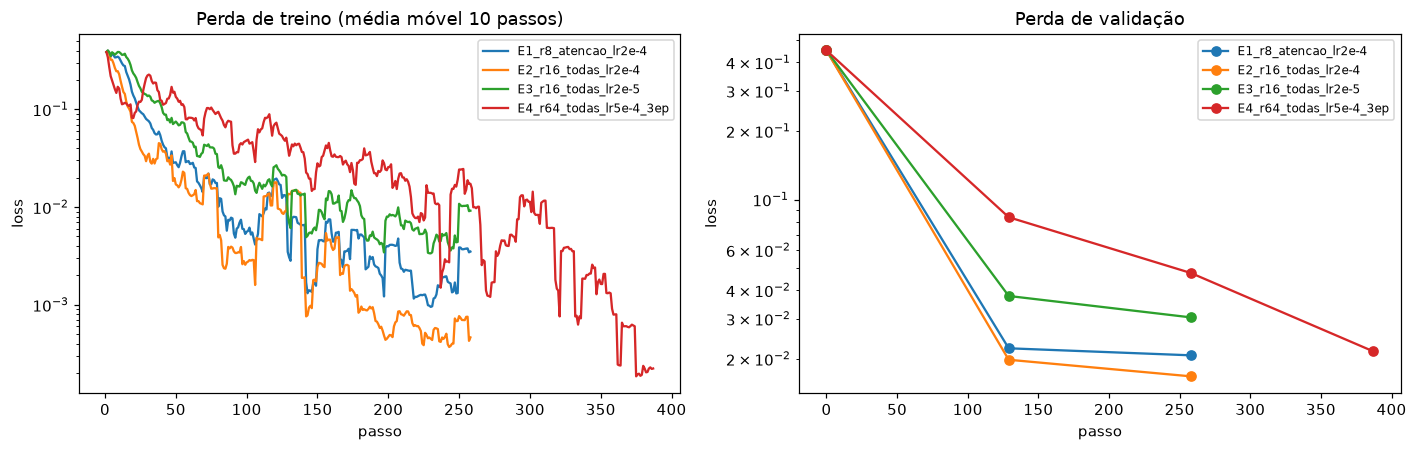

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
for nome, h in historicos.items():
    s = pd.Series(h["loss"]).rolling(10, min_periods=1).mean()
    eixos[0].plot(h["passo"], s, label=nome)
    eixos[1].plot(h["val_passo"], h["val_loss"], marker="o", label=nome)
eixos[0].set(title="Perda de treino (média móvel 10 passos)", xlabel="passo", ylabel="loss", yscale="log")
eixos[1].set(title="Perda de validação", xlabel="passo", ylabel="loss", yscale="log")
eixos[0].legend(fontsize=8); eixos[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(PASTA_RES / "curvas_perda.png"); plt.show()

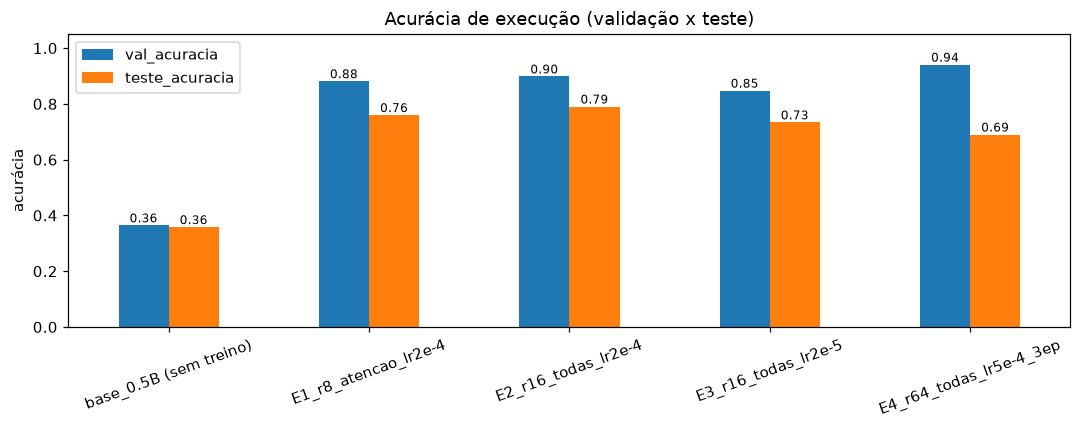

In [12]:
t = pd.DataFrame(resultados).T
fig, ax = plt.subplots(figsize=(10, 4))
t[["val_acuracia", "teste_acuracia"]].astype(float).plot.bar(ax=ax, rot=20)
ax.set(title="Acurácia de execução (validação x teste)", ylim=(0, 1.05), ylabel="acurácia")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(PASTA_RES / "acuracia_experimentos.png"); plt.show()

Telemetria da GPU durante o treino do experimento E4 (o mais pesado):

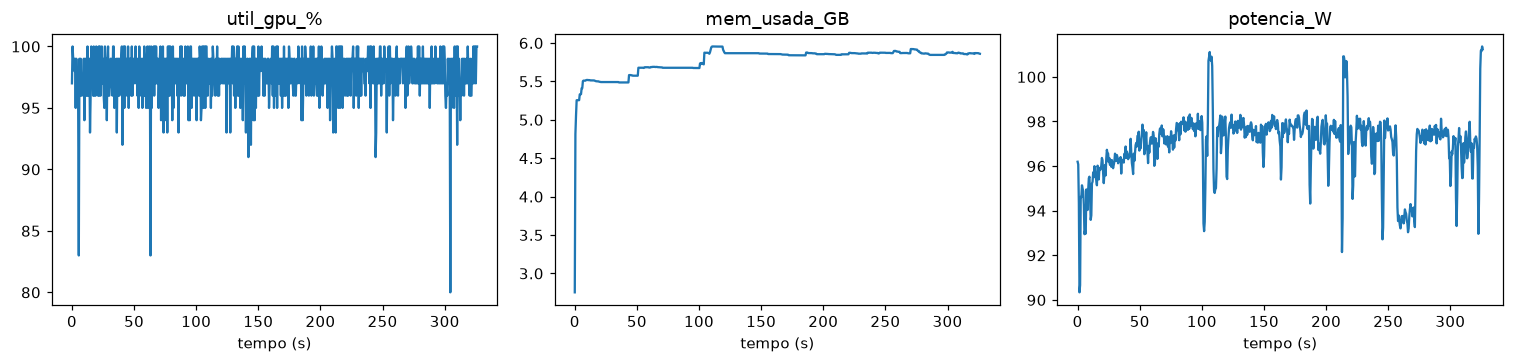

,t,util_gpu_%,mem_usada_GB,temp_C,potencia_W
count,651.0,651.0,651.0,651.0,651.0
mean,163.1,97.7,5.8,66.0,97.0
std,94.4,2.1,0.2,1.9,1.4
min,0.0,80.0,2.8,58.0,90.3
25%,81.5,96.0,5.7,66.0,96.4
50%,163.1,98.0,5.9,67.0,97.3
75%,244.6,99.0,5.9,67.0,97.8
max,326.1,100.0,6.0,68.0,101.4


In [13]:
tele = telemetria["E4_r64_todas_lr5e-4_3ep"]
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, col in zip(eixos, ["util_gpu_%", "mem_usada_GB", "potencia_W"]):
    ax.plot(tele["t"], tele[col]); ax.set(title=col, xlabel="tempo (s)")
plt.tight_layout(); plt.savefig(PASTA_RES / "telemetria_gpu.png"); plt.show()
tele.describe().round(1)

## 6. Teste de parâmetros de geração
Usando o melhor experimento (escolhido pela **acurácia de validação**), comparamos decodificação *greedy* com amostragem
em diferentes temperaturas.

In [14]:
melhor_exp = max(EXPERIMENTOS, key=lambda n: (resultados[n]["val_acuracia"], -resultados[n]["val_loss_final"]))
print("Melhor experimento (validação):", melhor_exp)
tok = AutoTokenizer.from_pretrained(MODELO_PEQUENO)
base = AutoModelForCausalLM.from_pretrained(MODELO_PEQUENO, dtype=torch.bfloat16).to(DISPOSITIVO)
modelo = PeftModel.from_pretrained(base, PASTA_MOD / melhor_exp)

CONFIGS_GERACAO = {
    "greedy": dict(do_sample=False),
    "T=0.3, top_p=0.9": dict(do_sample=True, temperature=0.3, top_p=0.9),
    "T=0.7, top_p=0.9": dict(do_sample=True, temperature=0.7, top_p=0.9),
    "T=1.0, top_p=1.0": dict(do_sample=True, temperature=1.0, top_p=1.0),
    "T=1.5, top_p=1.0": dict(do_sample=True, temperature=1.5, top_p=1.0),
}
res_geracao = {}
for nome, kw in CONFIGS_GERACAO.items():
    torch.manual_seed(0)
    m, _ = avaliar(modelo, tok, teste, con, **kw)
    res_geracao[nome] = m
    print(f"{nome:18s} -> {m}")
df_ger = pd.DataFrame(res_geracao).T.astype(float).round(3)
df_ger

Melhor experimento (validação): E4_r64_todas_lr5e-4_3ep


greedy             -> {'acuracia_execucao': 0.6899563318777293, 'match_exato': 0.6812227074235808, 'sql_valido': 0.9344978165938864, 'tempo_geracao_s': 49.16010642051697}


T=0.3, top_p=0.9   -> {'acuracia_execucao': 0.6986899563318777, 'match_exato': 0.6899563318777293, 'sql_valido': 0.9301310043668122, 'tempo_geracao_s': 52.42184567451477}


T=0.7, top_p=0.9   -> {'acuracia_execucao': 0.6899563318777293, 'match_exato': 0.6812227074235808, 'sql_valido': 0.9126637554585153, 'tempo_geracao_s': 52.60934114456177}


T=1.0, top_p=1.0   -> {'acuracia_execucao': 0.6550218340611353, 'match_exato': 0.6375545851528385, 'sql_valido': 0.8733624454148472, 'tempo_geracao_s': 48.25452470779419}


T=1.5, top_p=1.0   -> {'acuracia_execucao': 0.5851528384279476, 'match_exato': 0.5764192139737991, 'sql_valido': 0.8122270742358079, 'tempo_geracao_s': 49.084625482559204}


,acuracia_execucao,match_exato,sql_valido,tempo_geracao_s
greedy,0.690,0.681,0.934,49.160
"T=0.3, top_p=0.9",0.699,0.690,0.930,52.422
"T=0.7, top_p=0.9",0.690,0.681,0.913,52.609
"T=1.0, top_p=1.0",0.655,0.638,0.873,48.255
"T=1.5, top_p=1.0",0.585,0.576,0.812,49.085


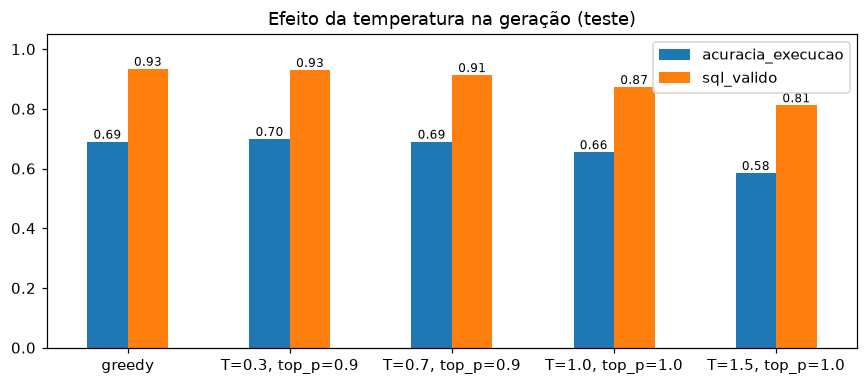

In [15]:
ax = df_ger[["acuracia_execucao", "sql_valido"]].plot.bar(figsize=(8, 3.6), rot=0, ylim=(0, 1.05),
                                                         title="Efeito da temperatura na geração (teste)")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(PASTA_RES / "parametros_geracao.png"); plt.show()
del modelo, base; liberar()

## 7. Modelo maior: Qwen2.5-Coder-1.5B-Instruct
Avaliamos o modelo de 1,5 B sem treino e com fine-tuning usando a melhor configuração encontrada. Para caber com folga
nos 8 GB usamos *gradient checkpointing* (troca memória por recomputação).

In [16]:
tok = AutoTokenizer.from_pretrained(MODELO_GRANDE)
modelo = AutoModelForCausalLM.from_pretrained(MODELO_GRANDE, dtype=torch.bfloat16).to(DISPOSITIVO)
print(avaliar_modelo("base_1.5B (sem treino)", modelo, tok))
del modelo; liberar()

nome_grande = "E5_1.5B_" + melhor_exp.split("_", 1)[1]
cfg_grande = {**EXPERIMENTOS[melhor_exp], "modelo": MODELO_GRANDE, "gradient_checkpointing": True, "micro_batch": 8}
EXPERIMENTOS[nome_grande] = cfg_grande
print(f"=== {nome_grande} ===")
modelo, tok, hist, tele, info = treinar(cfg_grande)
historicos[nome_grande], telemetria[nome_grande] = hist, tele
print(" ", avaliar_modelo(nome_grande, modelo, tok, extra=info))
modelo.save_pretrained(PASTA_MOD / nome_grande)
del modelo; liberar()

{'val_acuracia': 0.4152542372881356, 'teste_acuracia': 0.4585152838427948, 'teste_match_exato': 0.2838427947598253, 'teste_sql_valido': 0.8078602620087336, 'tempo_geracao_teste_s': 48.62232065200806}


=== E5_1.5B_r64_todas_lr5e-4_3ep ===


  época 1/3: loss treino (últ. 10) = 0.0399 | loss validação = 0.1080


  época 2/3: loss treino (últ. 10) = 0.0088 | loss validação = 0.0399


  época 3/3: loss treino (últ. 10) = 0.0022 | loss validação = 0.0351


  {'val_acuracia': 0.8983050847457628, 'teste_acuracia': 0.7729257641921398, 'teste_match_exato': 0.7729257641921398, 'teste_sql_valido': 0.9781659388646288, 'tempo_geracao_teste_s': 68.25507259368896, 'tempo_treino_s': 1094.9989702701569, 'vram_pico_GB': 4.637607574462891, 'params_treinaveis_M': 73.859072, 'params_treinaveis_%': 4.5660415221868735, 'val_loss_final': 0.03507382805315898, 'util_gpu_media_%': np.float64(99.74598807886291)}


## 8. Avaliação final e análise de erros

In [17]:
final = pd.DataFrame(resultados).T
final = final[[c for c in colunas + ["tempo_geracao_teste_s"] if c in final]].astype(float).round(3)
final.to_csv(PASTA_RES / "resultados_experimentos.csv")
final

,val_acuracia,teste_acuracia,teste_match_exato,teste_sql_valido,val_loss_final,tempo_treino_s,vram_pico_GB,params_treinaveis_M,params_treinaveis_%,util_gpu_media_%,tempo_geracao_teste_s
base_0.5B (sem treino),0.364,0.358,0.218,0.651,NaN,NaN,NaN,NaN,NaN,NaN,45.613
E1_r8_atencao_lr2e-4,0.881,0.760,0.751,0.921,0.021,163.865,3.021,1.081,0.218,96.878,47.029
E2_r16_todas_lr2e-4,0.898,0.790,0.786,0.969,0.017,224.403,3.760,8.798,1.750,97.520,47.428
E3_r16_todas_lr2e-5,0.847,0.734,0.716,0.908,0.030,219.996,3.760,8.798,1.750,97.380,58.517
E4_r64_todas_lr5e-4_3ep,0.941,0.690,0.681,0.934,0.022,326.594,4.269,35.193,6.650,97.670,51.705
base_1.5B (sem treino),0.415,0.459,0.284,0.808,NaN,NaN,NaN,NaN,NaN,NaN,48.622
E5_1.5B_r64_todas_lr5e-4_3ep,0.898,0.773,0.773,0.978,0.035,1094.999,4.638,73.859,4.566,99.746,68.255


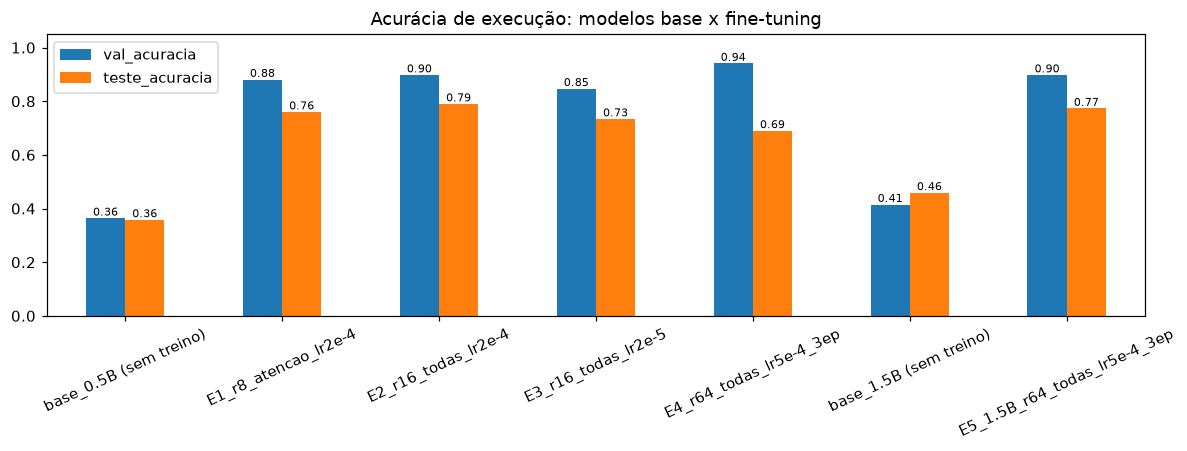

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.2))
final[["val_acuracia", "teste_acuracia"]].plot.bar(ax=ax, rot=25, ylim=(0, 1.05),
                                                   title="Acurácia de execução: modelos base x fine-tuning")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(PASTA_RES / "comparacao_final.png"); plt.show()

In [19]:
# Escolha final: maior acurácia na VALIDAÇÃO entre os modelos com fine-tuning; empate -> menor tempo de geração
candidatos = [n for n in EXPERIMENTOS]
melhor = max(candidatos, key=lambda n: (resultados[n]["val_acuracia"], -resultados[n]["tempo_geracao_teste_s"]))
print("Modelo final escolhido:", melhor, "| base:", EXPERIMENTOS[melhor]["modelo"])

def por_tipo(nome):
    return pd.DataFrame(predicoes[nome]).groupby("tipo_teste")["correto"].mean()

pd.DataFrame({"base_0.5B": por_tipo("base_0.5B (sem treino)"), "base_1.5B": por_tipo("base_1.5B (sem treino)"),
              "melhor_0.5B": por_tipo(melhor_exp), "final": por_tipo(melhor)}).round(3)

Modelo final escolhido: E4_r64_todas_lr5e-4_3ep | base: Qwen/Qwen2.5-Coder-0.5B-Instruct


,base_0.5B,base_1.5B,melhor_0.5B,final
tipo_teste,,,,
parafrase_inedita,0.317,0.410,0.669,0.669
tipo_inedito,0.467,0.533,0.467,0.467
valores_novos,0.378,0.533,0.978,0.978


In [20]:
regs = pd.DataFrame(predicoes[melhor])
print("Acurácia por template (teste) — piores primeiro:")
regs.groupby("template")["correto"].agg(["mean", "count"]).sort_values("mean").head(10).round(2)

Acurácia por template (teste) — piores primeiro:


,mean,count
template,,
conta_clientes_estado,0.00,5
pedidos_acima_valor,0.00,5
produtos_por_categoria,0.00,1
quantidade_vendida_categoria,0.00,5
top_produtos_baratos_categoria,0.00,5
pedidos_estado_status,0.07,15
clientes_estado,0.20,5
clientes_cidade_cadastro_ano,0.33,15
preco_produto,0.40,10


In [21]:
erros = regs[~regs["correto"]][["tipo_teste", "pergunta", "sql", "pred"]]
print(f"{len(erros)} erros de {len(regs)} exemplos de teste")
erros.head(12)

71 erros de 229 exemplos de teste


,tipo_teste,pergunta,sql,pred
6,parafrase_inedita,Quem são os clientes localizados em SP?,SELECT nome FROM clientes WHERE estado = 'SP';,SELECT nome FROM clientes WHERE cidade = 'SP';
7,parafrase_inedita,Quem são os clientes localizados em PR?,SELECT nome FROM clientes WHERE estado = 'PR';,SELECT nome FROM clientes WHERE cidade = 'PR';
8,parafrase_inedita,Quem são os clientes localizados em SC?,SELECT nome FROM clientes WHERE estado = 'SC';,SELECT nome FROM clientes WHERE cidade = 'SC';
9,parafrase_inedita,Quem são os clientes localizados em CE?,SELECT nome FROM clientes WHERE estado = 'CE';,SELECT nome FROM clientes WHERE cidade = 'CE';
28,parafrase_inedita,"Na categoria Eletrônicos, quais os 3 produtos mais em conta?","SELECT nome, preco FROM produtos WHERE categoria = 'Eletrônicos' ORDER BY preco ASC LIMIT 3;","SELECT nome, preco FROM produtos WHERE categoria = 'Eletrônicos' ORDER BY preco DESC LIMIT 3;"
29,parafrase_inedita,"Na categoria Brinquedos, quais os 5 produtos mais em conta?","SELECT nome, preco FROM produtos WHERE categoria = 'Brinquedos' ORDER BY preco ASC LIMIT 5;","SELECT nome, preco FROM produtos WHERE categoria = 'Brinquedos' ORDER BY preco DESC LIMIT 5;"
30,parafrase_inedita,"Na categoria Livros, quais os 3 produtos mais em conta?","SELECT nome, preco FROM produtos WHERE categoria = 'Livros' ORDER BY preco ASC LIMIT 3;","SELECT nome, preco FROM produtos WHERE categoria = 'Livros' ORDER BY preco DESC LIMIT 3;"
31,parafrase_inedita,"Na categoria Casa, quais os 3 produtos mais em conta?","SELECT nome, preco FROM produtos WHERE categoria = 'Casa' ORDER BY preco ASC LIMIT 3;","SELECT nome, preco FROM produtos WHERE categoria = 'Casa' ORDER BY preco DESC LIMIT 3;"
32,parafrase_inedita,"Na categoria Roupas, quais os 10 produtos mais em conta?","SELECT nome, preco FROM produtos WHERE categoria = 'Roupas' ORDER BY preco ASC LIMIT 10;","SELECT nome, preco FROM produtos WHERE categoria = 'Roupas' ORDER BY preco DESC LIMIT 10;"
46,parafrase_inedita,Qual o total de itens cadastrados por categoria?,"SELECT categoria, COUNT(*) FROM produtos GROUP BY categoria;","SELECT categoria, SUM(usuarios.cadastro) FROM usuarios GROUP BY categoria;"


### Comparação qualitativa: modelo base x modelo treinado

In [22]:
base_regs = pd.DataFrame(predicoes["base_0.5B (sem treino)"])
amostra = regs.sample(8, random_state=3).index
pd.DataFrame({"pergunta": regs.loc[amostra, "pergunta"], "base_0.5B": base_regs.loc[amostra, "pred"],
              "ok_base": base_regs.loc[amostra, "correto"], "treinado": regs.loc[amostra, "pred"],
              "ok_treinado": regs.loc[amostra, "correto"]})

,pergunta,base_0.5B,ok_base,treinado,ok_treinado
108,Como posso contatar Rodrigo Souza por e-mail?,SELECT email FROM clientes WHERE nome = 'Rodrigo Souza',True,SELECT email FROM clientes WHERE nome = 'Rodrigo Souza';,True
73,Quais 3 produtos tiveram mais unidades vendidas?,SELECT p.nome FROM produtos p JOIN itens_pedido ip ON p.id = ip.produto_id GROUP BY p.id ORDER BY SUM(ip.quantidade)...,False,"SELECT pr.nome, SUM(i.quantidade) AS total_vendido FROM itens_pedido i JOIN produtos pr ON i.produto_id = pr.id GROU...",True
15,Mostre os produtos Livros mais baratos que R$ 100.,"SELECT p.id, p.nome, p.preco\nFROM produtos p\nJOIN itens_pedido ip ON p.id = ip.produto_id\nWHERE p.categoria = 'Li...",False,"SELECT nome, preco FROM produtos WHERE categoria = 'Livros' AND preco < 100;",True
187,"Dos clientes de AM, quantos pedidos estão enviados?",SELECT COUNT(*) FROM pedidos WHERE cliente_id IN (SELECT id FROM clientes WHERE cidade = 'América') AND status = 'en...,False,SELECT COUNT(*) FROM clientes WHERE estado = 'AM';,True
3,Me diga a quantidade de clientes que vivem em Niterói.,SELECT COUNT(*) FROM clientes WHERE cidade = 'Niterói',True,SELECT COUNT(*) FROM clientes WHERE cidade = 'Niterói';,True
40,Total de pedidos que estão cancelados.,SELECT COUNT(*) FROM pedidos WHERE status = 'cancelado',True,SELECT COUNT(*) FROM pedidos WHERE status = 'cancelado';,True
31,"Na categoria Casa, quais os 3 produtos mais em conta?","SELECT p.id, p.nome, p.categoria FROM produtos p JOIN itens_pedido ip ON p.id = ip.produto_id WHERE p.categoria = 'C...",False,"SELECT nome, preco FROM produtos WHERE categoria = 'Casa' ORDER BY preco DESC LIMIT 3;",False
173,Quais são os 5 clientes de Uberlândia que mais gastaram?,"SELECT c.id, c.nome, SUM(p.preco * i.quantidade) AS total_gasto\nFROM clientes c\nJOIN pedidos p ON c.id = p.cliente...",False,"SELECT c.nome, SUM(p.valor_total) AS total FROM clientes c JOIN pedidos p ON p.cliente_id = c.id WHERE c.cidade = 'U...",True


### Perguntas livres (escritas à mão, fora do dataset)
Avaliação qualitativa: o resultado da execução é mostrado para conferência manual.

In [23]:
tok = AutoTokenizer.from_pretrained(EXPERIMENTOS[melhor]["modelo"])
base = AutoModelForCausalLM.from_pretrained(EXPERIMENTOS[melhor]["modelo"], dtype=torch.bfloat16).to(DISPOSITIVO)
modelo = PeftModel.from_pretrained(base, PASTA_MOD / melhor)
from src.avaliacao import gerar_sql, executar
livres = [
    "Quantos pedidos foram entregues em 2024?",
    "Qual o produto mais caro da categoria Casa?",
    "Qual o estoque do produto Cubo Mágico?",
    "Quantos clientes temos na Bahia?",
    "Liste os clientes de Salvador.",
    "Quantos livros a loja já vendeu?",
]
for p, sql in zip(livres, gerar_sql(modelo, tok, livres)):
    res, erro = executar(con, sql)
    print(f"P: {p}\nSQL: {sql}\nResultado: {erro or res[:5]}\n")

P: Quantos pedidos foram entregues em 2024?
SQL: SELECT COUNT(*) FROM pedidos WHERE status = 'entregue' AND strftime('%Y', data_pedido) = '2024';
Resultado: [(366,)]

P: Qual o produto mais caro da categoria Casa?
SQL: SELECT nome, preco FROM produtos WHERE categoria = 'Casa' ORDER BY preco DESC LIMIT 1;
Resultado: [('Aspirador Robô', 1299.0)]

P: Qual o estoque do produto Cubo Mágico?
SQL: SELECT estoque FROM produtos WHERE nome = 'Cubo Mágico';
Resultado: [(63,)]

P: Quantos clientes temos na Bahia?
SQL: SELECT COUNT(*) FROM clientes WHERE cidade = 'Bahia';
Resultado: [(0,)]

P: Liste os clientes de Salvador.
SQL: SELECT nome FROM clientes WHERE estado = 'Salvador';
Resultado: []

P: Quantos livros a loja já vendeu?
SQL: SELECT COUNT(DISTINCT p.cliente_id) FROM pedidos p JOIN itens_pedido i ON i.pedido_id = p.id JOIN produtos pr ON pr.id = i.produto_id WHERE pr.categoria = 'Livros';
Resultado: [(177,)]



## 9. Salvando o melhor modelo para o frontend

In [24]:
destino = PASTA_MOD / "melhor"
if destino.exists(): shutil.rmtree(destino)
modelo.save_pretrained(destino)
tok.save_pretrained(destino)
info_final = {"experimento": melhor, "modelo_base": EXPERIMENTOS[melhor]["modelo"],
              "config": {k: v for k, v in EXPERIMENTOS[melhor].items() if k != "modelo"},
              "metricas": {k: float(v) for k, v in resultados[melhor].items()}}
(destino / "info.json").write_text(json.dumps(info_final, indent=2, ensure_ascii=False), encoding="utf-8")
(PASTA_RES / "resultados.json").write_text(json.dumps({"experimentos": resultados, "configs": EXPERIMENTOS,
    "geracao": res_geracao, "melhor": melhor}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(info_final, indent=2, ensure_ascii=False))
del modelo, base; liberar()

{
  "experimento": "E4_r64_todas_lr5e-4_3ep",
  "modelo_base": "Qwen/Qwen2.5-Coder-0.5B-Instruct",
  "config": {
    "batch": 8,
    "micro_batch": 4,
    "dropout": 0.05,
    "semente": 42,
    "r": 64,
    "alpha": 128,
    "alvos": [
      "q_proj",
      "k_proj",
      "v_proj",
      "o_proj",
      "gate_proj",
      "up_proj",
      "down_proj"
    ],
    "lr": 0.0005,
    "epocas": 3
  },
  "metricas": {
    "val_acuracia": 0.940677966101695,
    "teste_acuracia": 0.6899563318777293,
    "teste_match_exato": 0.6812227074235808,
    "teste_sql_valido": 0.9344978165938864,
    "tempo_geracao_teste_s": 51.704516887664795,
    "tempo_treino_s": 326.59391927719116,
    "vram_pico_GB": 4.269285678863525,
    "params_treinaveis_M": 35.192832,
    "params_treinaveis_%": 6.649873324344099,
    "val_loss_final": 0.021564366078696117,
    "util_gpu_media_%": 97.66973886328725
  }
}


## Conclusões

1. **Fine-tuning com LoRA funciona muito bem para a tarefa:** a acurácia de execução no teste foi de **35,8 %** (0,5 B sem
   treino) para **até 79,0 %** (E2), treinando só 1,7 % dos parâmetros em ~4 min na RTX 3050. O 0,5 B treinado supera o
   1,5 B sem treino (45,9 %). O % de SQL válido sobe de 65 % para 93–98 %.
2. **Hiperparâmetros:** LoRA em todas as camadas lineares (E2) foi melhor que só na atenção (E1); LR 10× menor (E3) ficou
   subtreinado; alta capacidade + LR alto + 3 épocas (E4) sobreajustou (melhor validação, pior teste entre os treinados).
3. **Modelo maior (1,5 B):** com a mesma configuração do E4 generalizou melhor (77,3 %), mas treinou 3,4× mais devagar.
4. **Geração:** *greedy* ou temperatura baixa (≤ 0,7) são equivalentes; temperatura ≥ 1 piora a acurácia e gera SQL inválido.
5. **Seleção e limitações:** o critério pré-definido (acurácia de validação) escolheu o E4, mas o E2 foi melhor no teste —
   a validação com uma única paráfrase por template é um sinal ruidoso. Não trocamos o modelo olhando o teste; o frontend
   permite escolher qualquer adaptador. Tipos de consulta nunca vistos no treino continuam difíceis (~47 %).
6. **Engenharia:** calcular os logits só nas posições da resposta reduziu a VRAM de ~14 GB para ~5 GB e o tempo por passo em 3×,
   o que viabilizou todos os experimentos na GPU de 8 GB.

O frontend (`app.py`) carrega os adaptadores salvos em `modelos/` e permite que o usuário digite perguntas, escolha o
modelo, ajuste os parâmetros de geração e veja o SQL e o resultado da consulta.